## **Visualizing Weather Trends: Ann Arbor, Michigan (2005–2015)**
This notebook analyzes daily climate data from the Global Historical Climatology Network daily (GHCN-Daily) dataset.

## 1. Data Loading and Preprocessing



In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from calendar import month_abbr

In [6]:
df = pd.read_csv('assets/fb441e62df2d58994928907a91895ec62c2c42e6cd075c2700843b89.csv')
df.head()

,ID,Date,Element,Data_Value
0,USW00094889,2014-11-12,TMAX,22
1,USC00208972,2009-04-29,TMIN,56
2,USC00200032,2008-05-26,TMAX,278
3,USC00205563,2005-11-11,TMAX,139
4,USC00200230,2014-02-27,TMAX,-106


Convert temperature values from tenths of degrees Celsius to degrees Celsius

In [7]:
# In this code cell, transform the Data_Value column
df["Data_Value_C"]=df["Data_Value"]/10
df

,ID,Date,Element,Data_Value,Data_Value_C
0,USW00094889,2014-11-12,TMAX,22,2.2
1,USC00208972,2009-04-29,TMIN,56,5.6
2,USC00200032,2008-05-26,TMAX,278,27.8
3,USC00205563,2005-11-11,TMAX,139,13.9
4,USC00200230,2014-02-27,TMAX,-106,-10.6
...,...,...,...,...,...
165080,USC00205822,2015-06-09,TMAX,256,25.6
165081,USC00205822,2009-10-06,TMAX,167,16.7
165082,USC00205050,2014-07-14,TMAX,283,28.3
165083,USC00200230,2006-11-29,TMIN,117,11.7


Separate maximum and minimum temperatures

In [8]:
Tmax_df = df[df["Element"]=="TMAX"]
len(Tmax_df)

83063

In [9]:
Tmin_df = df[df["Element"]=="TMIN"]
len(Tmin_df)

82022

## 2. Historical Baseline (2005-2014) vs. Recent Data (2015)

create max and min temperature Series objects across all weather stations for each day, and remove Leap Year records (Feb 29) for consistent annual alignment

In [10]:
# create a DataFrame of maximum temperature by date
Tmax_maximos=Tmax_df.groupby("Date")["Data_Value_C"].max()    ##use groupby to get the max temp by date
Tmax_df = pd.merge(Tmax_df, Tmax_maximos, on=["Date", "Data_Value_C"])   ##merge the grouped df with the original df
Tmax_df = Tmax_df.drop_duplicates(subset=["Date"]).reset_index(drop=True)##drop the duplicates since there are records for the same date whit diferent ID
print("Tmax_df lenght with the  records for February 29:",len(Tmax_df)) ##check the df lenght
Tmax_df=Tmax_df[~Tmax_df["Date"].str.contains(r'-02-29$')] ##drop the records for February 29
print("Tmax_df lenght without the  records for February 29:",len(Tmax_df)) ##validate the length

print("--"*50)
# create a DataFrame of minimum temperatures by date
Tmin_minimos=Tmin_df.groupby("Date")["Data_Value_C"].min()    ##use groupby to get the max temp by date
Tmin_df = pd.merge(Tmin_df, Tmin_minimos, on=["Date", "Data_Value_C"])   ##merge the grouped df with the original df
Tmin_df = Tmin_df.drop_duplicates(subset=["Date"]).reset_index(drop=True)##drop the duplicates since there are records for the same date whit diferent ID
print("Tmin_df lenght with the  records for February 29:",len(Tmin_df)) ##check the df lenght
Tmin_df=Tmin_df[~Tmin_df["Date"].str.contains(r'-02-29$')] ##drop the records for February 29
print("Tmin_df lenght without the  records for February 29:",len(Tmin_df)) ##validate the length


Tmax_df lenght with the  records for February 29: 4017
Tmax_df lenght without the  records for February 29: 4015
----------------------------------------------------------------------------------------------------
Tmin_df lenght with the  records for February 29: 4017
Tmin_df lenght without the  records for February 29: 4015


Split historical period (2005-2014) and target year (2015) and Strip year to retain MM-DD format for annual grouping


In [11]:
#separate the df by years
Tmax_05_14 = Tmax_df[Tmax_df["Date"] < "2015-01-01"].copy()
Tmax_15    = Tmax_df[Tmax_df["Date"] >= "2015-01-01"].copy()
Tmin_05_14 = Tmin_df[Tmin_df["Date"] < "2015-01-01"].copy()
Tmin_15    = Tmin_df[Tmin_df["Date"] >= "2015-01-01"].copy()

#remove the year for all dates in all dataframes
for df in [Tmax_05_14, Tmax_15, Tmin_05_14, Tmin_15]:
    df["Date"] = df["Date"].str.replace(r'^\d{4}-', '', regex=True)

#group to get max an min by day
Tmax_05_14 = Tmax_05_14.groupby("Date")["Data_Value_C"].max().reset_index()
Tmin_05_14 = Tmin_05_14.groupby("Date")["Data_Value_C"].min().reset_index()
Tmax_15 = Tmax_15.groupby("Date")["Data_Value_C"].max().reset_index()
Tmin_15 = Tmin_15.groupby("Date")["Data_Value_C"].min().reset_index()

#sort by date
for df in [Tmax_05_14, Tmin_05_14, Tmax_15, Tmin_15]:
    df.sort_values("Date", inplace=True)
    df.reset_index(drop=True, inplace=True)

#check lenghts
print("Tmax 2005-2014 length:", len(Tmax_05_14))
print("Tmin 2005-2014 length:", len(Tmin_05_14))
print("Tmax 2015 length:", len(Tmax_15))
print("Tmin 2015 length:", len(Tmin_15))

Tmax 2005-2014 length: 365
Tmin 2005-2014 length: 365
Tmax 2015 length: 365
Tmin 2015 length: 365


## 3. Identify Record-Breaking Events in 2015

In [12]:
#get the points on 2015 where the themperature is higher or lower
y_2015_high = Tmax_15[Tmax_15["Data_Value_C"]>Tmax_05_14["Data_Value_C"]]["Data_Value_C"]
x_2015_high = Tmax_15[Tmax_15["Data_Value_C"]>Tmax_05_14["Data_Value_C"]]["Date"]
y_2015_low = Tmin_15[Tmin_15["Data_Value_C"]<Tmin_05_14["Data_Value_C"]]["Data_Value_C"]
x_2015_low = Tmin_15[Tmin_15["Data_Value_C"]<Tmin_05_14["Data_Value_C"]]["Date"]

# 4. Data Visualization

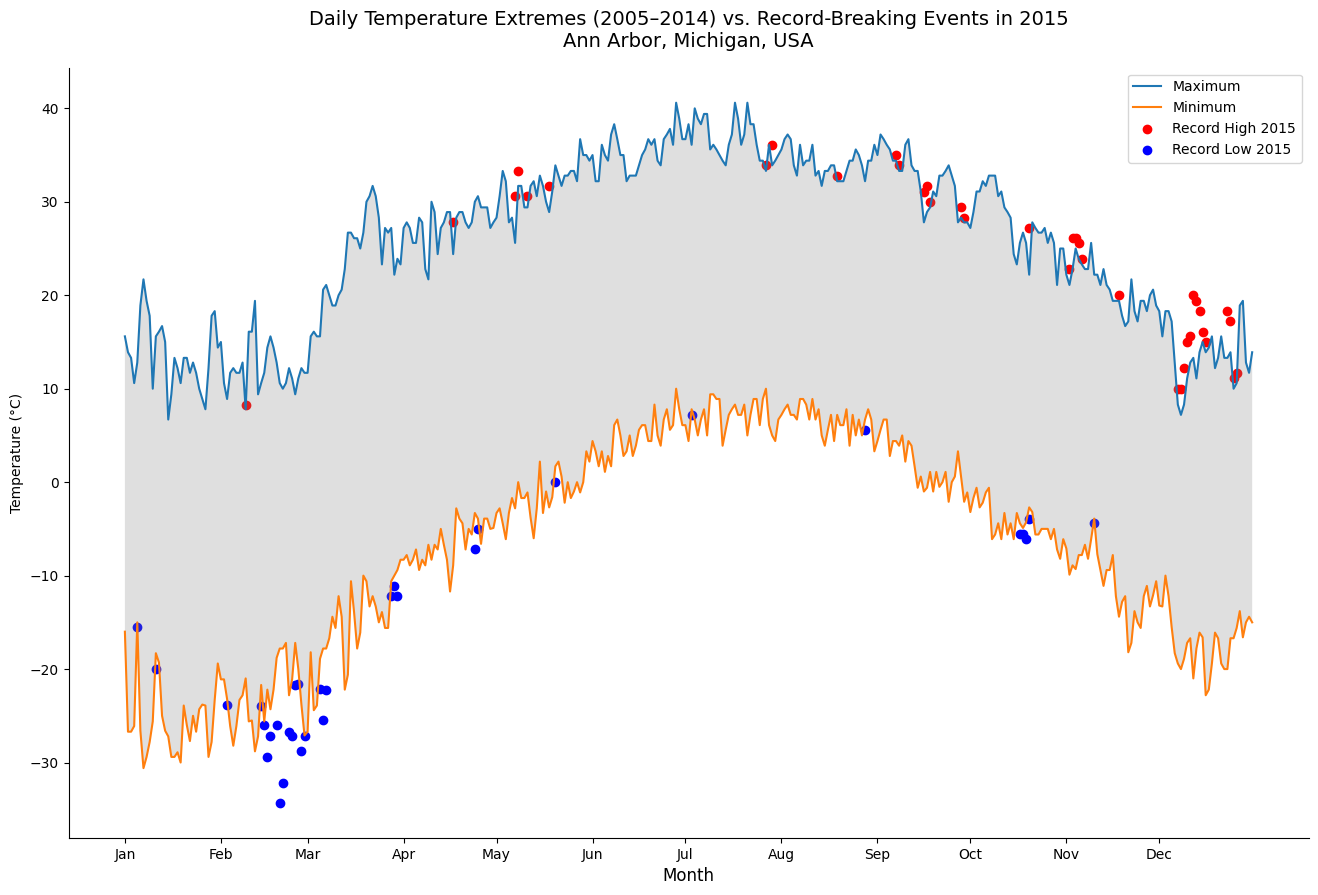

In [15]:
#define x and y
y_max=Tmax_05_14["Data_Value_C"]
y_min=Tmin_05_14["Data_Value_C"]

x_max=Tmax_05_14["Date"]
x_min=Tmin_05_14["Date"]

#define the day on which each month begins
month_start_dates = [
    '01-01', '02-01', '03-01', '04-01', '05-01', '06-01',
    '07-01', '08-01', '09-01', '10-01', '11-01', '12-01'
]
#get the months abrebiation omiting the first position which is empty
months_names = list(month_abbr)[1:]

#put your plotting code here!
plt.figure(figsize=(16, 10))
plt.plot(x_max,y_max,label="Maximum")# Historical daily maximum and minimum lines
plt.plot(x_min,y_min,label="Minimum")
plt.scatter(x_2015_high,y_2015_high,color="red",label="Record High 2015")# Scatter points for 2015 record-breaking days
plt.scatter(x_2015_low,y_2015_low,color="blue",label="Record Low 2015")
plt.title('Daily Temperature Extremes (2005–2014) vs. Record-Breaking Events in 2015\nAnn Arbor, Michigan, USA', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel("Temperature (°C)")
plt.fill_between(x_max, y_min, y_max, facecolor='gray', alpha=0.25)# Shaded area between historical record highs and lows
plt.xticks(ticks=month_start_dates, labels=months_names)# Formatting axes and labels
plt.legend()
plt.gca().spines['top'].set_visible(False) #hide the top and right borders
plt.gca().spines['right'].set_visible(False)
plt.savefig('assets/temperature_trends.png', dpi=300)
plt.show()


## Conclusions and Insights

1. **Extreme Cold Records (February 2015):** In early 2015, Ann Arbor experienced a significantly intense cold wave during the month of February, breaking historical minimum temperature records set between 2005 and 2014 on multiple consecutive occasions, reaching temperatures below -25°C.

2. **Spring/Autumn Trend:** The maximum temperature records broken during 2015 occurred predominantly during late spring and autumn/winter months (December), demonstrating warm temperature anomalies during transitional seasons.